## Initial Data Load

In [1]:
pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [3]:
# Load the dataset
raw_df = pd.read_csv("./dataset/WOD_1931-2025.csv")

C:\Users\simra\AppData\Local\Temp\ipykernel_18280\898108334.py:2: DtypeWarning: Columns (19,22,31,32,34,35,38,39) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_df = pd.read_csv("./dataset/WOD_1931-2025.csv")


## Feature Selection

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [5]:
fs_df = raw_df.copy()

# Replace invalid missing-value indicators
fs_df = fs_df.replace([-9999, "-9999"], np.nan)

# Convert relevant columns
fs_df["Year"] = pd.to_numeric(
    fs_df["Year"], errors="coerce"
)

# Keep records from 2011 onwards
fs_df = fs_df[
    fs_df["Year"].between(1998, 2025)
].copy()

# Remove records with missing AreaCat
fs_df = fs_df.dropna(
    subset=["AreaCat", "Year", "AreaHa"]
)

# Create classification target
fs_df["AreaCatModified"] = np.where(
    fs_df["AreaCat"] == "< 1",
    0,
    1
).astype(int)

# Target
target = "AreaCatModified"

print("Dataset shape:", fs_df.shape)

print("\nTarget distribution:")
print(fs_df[target].value_counts())

print("\nTarget percentage:")
print(
    (fs_df[target].value_counts(normalize=True) * 100).round(2)
)
fs_df.sample(1)

Dataset shape: (125407, 110)

Target distribution:
AreaCatModified
0    119639
1      5768
Name: count, dtype: int64

Target percentage:
AreaCatModified
0    95.4
1     4.6
Name: proportion, dtype: float64


,ID,Source,OrgID,X,Y,Lat,Lon,Day,Month,Year,...,PrecipNoon,Precip24hr,Precip48hr,Precip72hr,NoRain1,NoRain2,NoRain3,SOI,ENSO,AreaCatModified
81230,WOD51028,FENZ,F1754444,1603246.0,5429741.0,-41.283763,173.038763,26,12,2014,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-5.5,Neutral,0


In [6]:
# Columns that must not be used as predictors
exclude_columns = [
    "AreaHa",
    "AreaCat",
    "AreaCatModified",
    "Year"
]

# # Additional potentially derived or post-event fields
# exclude_columns += [
#     "AreaCatModified",
#     "ROS",
#     "HFI",
#     "Source_DOC",
#     "Source_FENZ",
#     "OrgID",
#     "WxID",
#     "ROSNoon",
#     "HFINoon"
# ]

X = fs_df.drop(
    columns=exclude_columns,
    errors="ignore"
)

y = fs_df[target]

print("Total records:", len(fs_df))
print("Predictor features:", X.shape[1])

print("\nPredictor columns:")
print(X.columns.tolist())

Total records: 125407
Predictor features: 106

Predictor columns:
['ID', 'Source', 'OrgID', 'X', 'Y', 'Lat', 'Lon', 'Day', 'Month', 'Time', 'Hour', 'Minute', 'Season', 'StartFY', 'EndFY', 'FY', 'OrgVeg', 'IgnSource', 'FENZDist', 'OrgIDDrop', 'Elev', 'MinElev', 'MaxElev', 'Slope', 'MinSlope', 'MaxSlope', 'AspectDeg', 'AspectCar', 'AspectCar2', 'AspectCar3', 'LandCvr', 'LandCvr2', 'LandCvr3', 'FuelType', 'Landform', 'Landform2', 'Landform3', 'ClimZnName', 'WxName', 'WxID', 'WxDist', 'FuelClass', 'Temp', 'TempNoon', 'TempMax8B', 'TempMin8B', 'TempAvg8B', 'TempMax8A', 'TempMin8A', 'TempAvg8A', 'RH', 'RHNoon', 'RHMax8B', 'RHMin8B', 'RHAvg8B', 'RHMax8A', 'RHMin8A', 'RHAvg8A', 'WS', 'WSNoon', 'WSMax8B', 'WSMin8B', 'WSAvg8B', 'WSMax8A', 'WSMin8A', 'WSAvg8A', 'WD', 'SoilMoist', 'SoilTemp', 'FFMCNoon', 'FFMC', 'FFMC8B', 'FFMC8A', 'ISINoon', 'ISI', 'ISI8B', 'ISI8A', 'FWINoon', 'FWI', 'FWI8B', 'FWI8A', 'FDCNoon', 'FDC', 'FDC8B', 'FDC8A', 'HFINoon', 'HFI', 'HFI8B', 'HFI8A', 'ROSNoon', 'ROS', 'ROS8B

In [7]:
train_mask = fs_df["Year"].between(1998, 2012)
val_mask = fs_df["Year"].between(2013, 2019)

X_train_fs = X.loc[train_mask].copy()
y_train_fs = y.loc[train_mask].copy()

X_val_fs = X.loc[val_mask].copy()
y_val_fs = y.loc[val_mask].copy()

print("Training rows:", len(X_train_fs))
print("Validation rows:", len(X_val_fs))

print("\nTraining target distribution:")
print(y_train_fs.value_counts(normalize=True) * 100)

print("\nValidation target distribution:")
print(y_val_fs.value_counts(normalize=True) * 100)

Training rows: 68473
Validation rows: 32791

Training target distribution:
AreaCatModified
0    95.165978
1     4.834022
Name: proportion, dtype: float64

Validation target distribution:
AreaCatModified
0    95.520112
1     4.479888
Name: proportion, dtype: float64


In [8]:
missing_pct = (
    X_train_fs.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Missing values by feature:")
display(
    missing_pct[missing_pct > 0].to_frame(
        "Missing_Percentage"
    ).round(2)
)

# Identify features completely missing in training
all_missing = X_train_fs.columns[
    X_train_fs.isna().all()
].tolist()

print("\nFeatures completely missing in training:")
print(all_missing)

# Remove completely missing features
X_train_fs = X_train_fs.drop(
    columns=all_missing
)

X_val_fs = X_val_fs.drop(
    columns=all_missing
)

Missing values by feature:


,Missing_Percentage
SoilMoist,100.00
SoilTemp,100.00
Landform3,99.95
Landform2,99.94
LandCvr3,99.82
...,...
LandCvr,1.08
Elev,0.67
Slope,0.60
FENZDist,0.05



Features completely missing in training:
['SoilMoist', 'SoilTemp']


In [9]:
numeric_features = X_train_fs.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train_fs.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 80
['X', 'Y', 'Lat', 'Lon', 'Day', 'Month', 'Hour', 'Minute', 'StartFY', 'EndFY', 'Elev', 'MinElev', 'MaxElev', 'Slope', 'MinSlope', 'MaxSlope', 'AspectDeg', 'WxID', 'WxDist', 'Temp', 'TempNoon', 'TempMax8B', 'TempMin8B', 'TempAvg8B', 'TempMax8A', 'TempMin8A', 'TempAvg8A', 'RH', 'RHNoon', 'RHMax8B', 'RHMin8B', 'RHAvg8B', 'RHMax8A', 'RHMin8A', 'RHAvg8A', 'WS', 'WSNoon', 'WSMax8B', 'WSMin8B', 'WSAvg8B', 'WSMax8A', 'WSMin8A', 'WSAvg8A', 'WD', 'FFMCNoon', 'FFMC', 'FFMC8B', 'FFMC8A', 'ISINoon', 'ISI', 'ISI8B', 'ISI8A', 'FWINoon', 'FWI', 'FWI8B', 'FWI8A', 'FDCNoon', 'FDC', 'FDC8B', 'FDC8A', 'HFINoon', 'HFI', 'HFI8B', 'HFI8A', 'ROSNoon', 'ROS', 'ROS8B', 'ROS8A', 'DMCNoon', 'DCNoon', 'BUINoon', 'DSRNoon', 'PrecipNoon', 'Precip24hr', 'Precip48hr', 'Precip72hr', 'NoRain1', 'NoRain2', 'NoRain3', 'SOI']

Categorical features: 24
['ID', 'Source', 'OrgID', 'Time', 'Season', 'FY', 'OrgVeg', 'IgnSource', 'FENZDist', 'OrgIDDrop', 'AspectCar', 'AspectCar2', 'AspectCar3', 'LandCvr', '

In [10]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [11]:
feature_model = Pipeline([
    ("preprocessing", preprocessor),

    ("random_forest", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        max_features=0.3,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using binary classification labels
feature_model.fit(
    X_train_fs,
    y_train_fs
)

print("Random Forest classification training completed.")

Random Forest classification training completed.


In [29]:
# Predict probabilities
y_val_proba = feature_model.predict_proba(
    X_val_fs
)[:, 1]

# Default threshold
y_val_pred = (
    y_val_proba >= 0.13
).astype(int)

print(
    "Validation PR-AUC:",
    average_precision_score(y_val_fs, y_val_proba)
)

print(
    "Validation ROC-AUC:",
    roc_auc_score(y_val_fs, y_val_proba)
)

print("\nClassification Report:")
print(
    classification_report(
        y_val_fs,
        y_val_pred,
        target_names=["Small Fire", "Large Fire"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_fs, y_val_pred))

Validation PR-AUC: 0.15380593005489318
Validation ROC-AUC: 0.8037656161918393

Classification Report:
              precision    recall  f1-score   support

  Small Fire       0.98      0.80      0.88     31322
  Large Fire       0.13      0.62      0.21      1469

    accuracy                           0.80     32791
   macro avg       0.55      0.71      0.55     32791
weighted avg       0.94      0.80      0.85     32791


Confusion Matrix:
[[25213  6109]
 [  560   909]]


In [30]:
# Access fitted preprocessing and classifier
preprocessor_fitted = feature_model.named_steps["preprocessing"]

rf_model = feature_model.named_steps["random_forest"]

# Get feature names after encoding
transformed_feature_names = (
    preprocessor_fitted.get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(30))

,Feature,Importance
136111,categorical__Time_NA:NA,0.061573
68554,categorical__Source_FENZ,0.057133
137765,categorical__LandCvr_Built-up Area (settlement),0.054565
68553,categorical__Source_DOC,0.048635
10,numeric__Elev,0.033450
137843,categorical__FuelType_Non-Fuel,0.031160
138164,categorical__FuelClass_Non Fuel,0.024971
64,numeric__ROSNoon,0.023669
93384,categorical__OrgID_F0571143,0.020604
60,numeric__HFINoon,0.019943


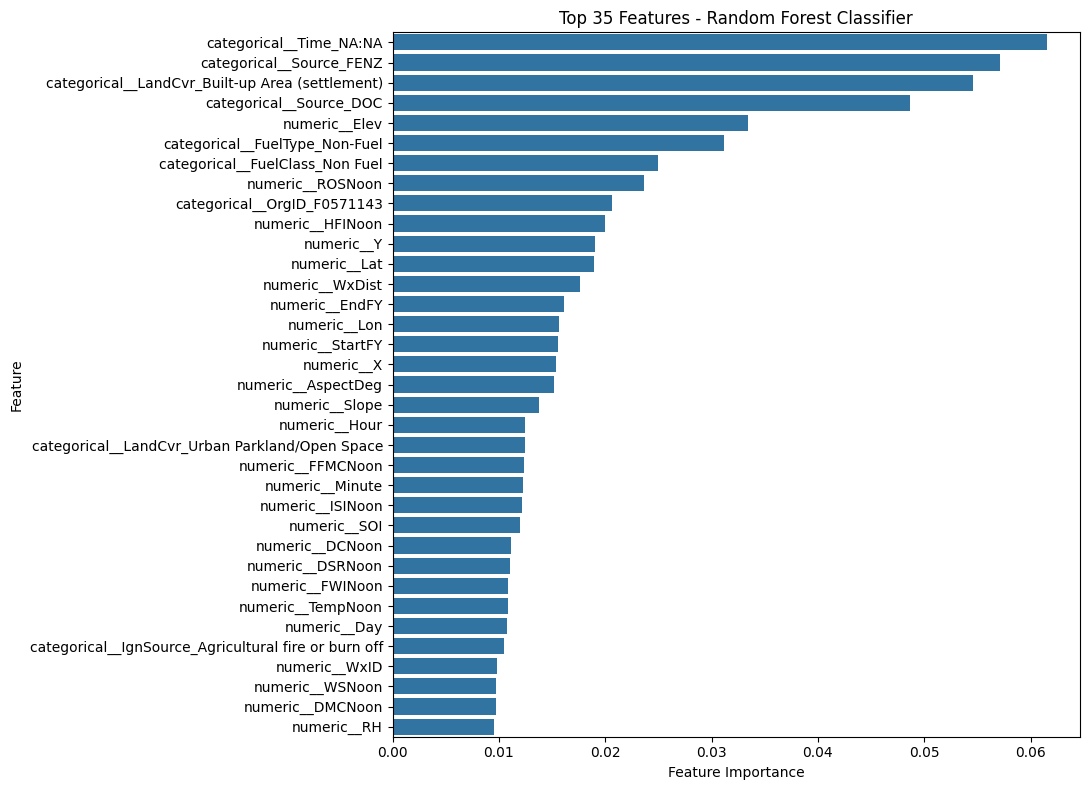

In [31]:
top_features = importance_df.head(35).sort_values(
    "Importance",
    ascending=False
)

plt.figure(figsize=(11, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 35 Features - Random Forest Classifier")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [32]:
periods = {
    "1998-2017": (1998, 2012),
    "2018-2019": (2013, 2019),
    "2020-2025": (2020, 2025)
}

results = []

for period, (start, end) in periods.items():

    subset = fs_df[
        fs_df["Year"].between(start, end)
    ]

    total = len(subset)
    large = (subset["AreaCatModified"] == 1).sum()
    small = (subset["AreaCatModified"] == 0).sum()

    results.append({
        "Period": period,
        "Total Fires": total,
        "Small Fires": small,
        "Large Fires": large,
        "Large Fire %": large / total * 100 if total else 0
    })

period_summary = pd.DataFrame(results)

display(period_summary.round(2))

,Period,Total Fires,Small Fires,Large Fires,Large Fire %
0,1998-2017,68473,65163,3310,4.83
1,2018-2019,32791,31322,1469,4.48
2,2020-2025,24143,23154,989,4.10
